
# Experiment 2

#Image Data Preprocessing

**Name:** Sneha Roychowdhury  
**Branch:** ECE-AI (2)  
**Semester:** 7  
**Subject:** Multimodal Data Analysis  

---

### Aim
To preprocess a CIFAR-10 image by resizing and augmentation, extract its deep features using the pre-trained VGG16 model, and perform classification using VGG16 with its top classification layers included.


## Objectives
To preprocess images by resizing, normalizing, and applying data augmentation techniques.

1. Load the CIFAR-10 dataset and display a sample image.
2. Resize the CIFAR-10 image from **32 × 32** to **224 × 224**, the standard VGG16 input size.
3. Apply image augmentation such as rotation, translation, zoom, and horizontal flipping.
4. Use a pre-trained **VGG16** network without its top layers to extract deep image features.
5. Observe and interpret the shape of the extracted feature tensor.
6. Use **VGG16 with `include_top=True`** to obtain ImageNet classification predictions for the resized CIFAR-10 image.



## Theory

### CIFAR-10
CIFAR-10 is a commonly used image-classification dataset containing **60,000 RGB images** of size **32 × 32 pixels** divided into 10 classes:

- airplane
- automobile
- bird
- cat
- deer
- dog
- frog
- horse
- ship
- truck

### Image Preprocessing
VGG16 expects images of size **224 × 224 × 3**. Therefore, the selected CIFAR-10 image is resized from 32 × 32 to 224 × 224.

Before passing the image to VGG16, `preprocess_input()` is applied. For the TensorFlow/Keras VGG16 implementation, this converts the image into the format expected by the pretrained model.

### Image Augmentation
Image augmentation creates modified versions of the original image while largely preserving its semantic content. This can improve robustness and reduce overfitting when training models.

In this experiment, augmentation includes:

- random horizontal flipping
- random rotation
- random zoom
- random translation

### VGG16
VGG16 is a convolutional neural network introduced by the Visual Geometry Group at Oxford. It contains 16 learnable weight layers and was originally trained on the **ImageNet** dataset.

Two forms of VGG16 are used here:

1. **`include_top=False`**  
   The final fully connected ImageNet classifier is removed. The remaining convolutional network acts as a **feature extractor**.

2. **`include_top=True`**  
   The original ImageNet classification layers are retained, producing probabilities over **1000 ImageNet classes**.

> **Important:** CIFAR-10 has 10 classes, while the pretrained VGG16 top layer predicts 1000 ImageNet classes. Therefore, the direct `include_top=True` prediction is an ImageNet classification of the resized CIFAR-10 image, not a trained CIFAR-10 classifier.


## Step 1: Import Required Libraries

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0



## Step 2: Load the CIFAR-10 Dataset

The dataset is loaded using `tensorflow.keras.datasets.cifar10`.

Only one sample image is required for this experiment, although the complete dataset is loaded by the API.


In [2]:

# Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape:", x_test.shape)
print("Test labels shape:", y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2637s 15us/step
Training data shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test data shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


## Step 3: Select and Display a CIFAR-10 Image

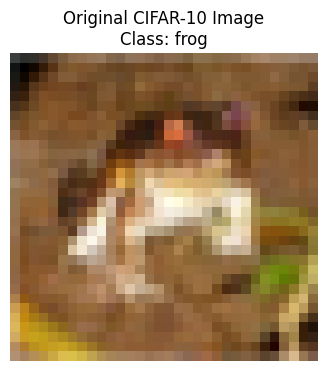

Original image shape: (32, 32, 3)
Class label: 6
Class name: frog


In [3]:

# Select one image from the training set
sample_index = 0
image = x_train[sample_index]
label = int(y_train[sample_index][0])

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Original CIFAR-10 Image\nClass: {class_names[label]}")
plt.axis("off")
plt.show()

print("Original image shape:", image.shape)
print("Class label:", label)
print("Class name:", class_names[label])



### Observation
The original CIFAR-10 image has shape:

\[
32 \times 32 \times 3
\]

where 3 represents the RGB channels.


## Step 4: Resize the Image to 224 × 224

Resized image shape: (224, 224, 3)


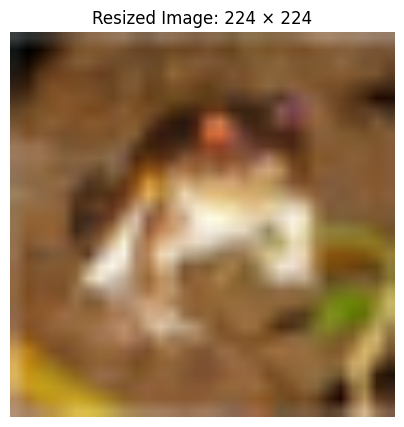

In [4]:

# Resize to the VGG16 input size
resized_image = tf.image.resize(image, (224, 224))

print("Resized image shape:", resized_image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(tf.cast(resized_image, tf.uint8))
plt.title("Resized Image: 224 × 224")
plt.axis("off")
plt.show()



### Observation
The image is now compatible with the standard VGG16 input shape:

\[
224 \times 224 \times 3
\]


## Step 5: Perform Image Augmentation

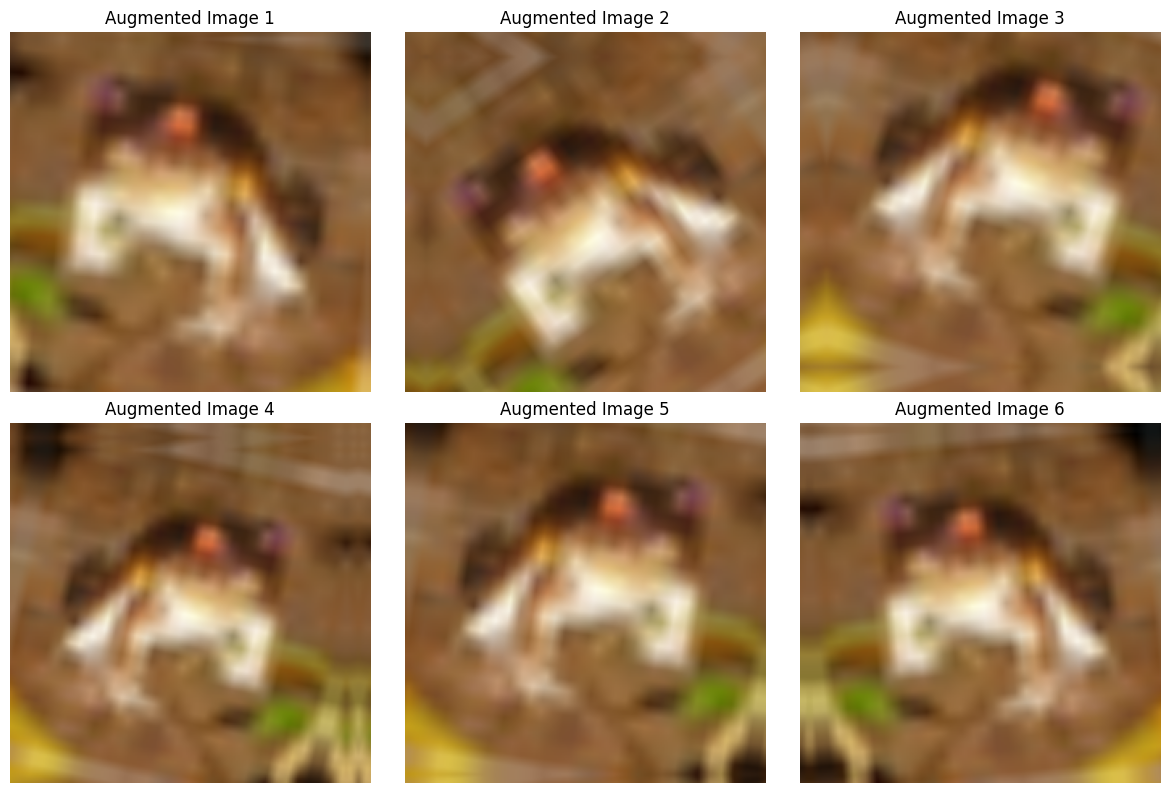

In [5]:

# Create an augmentation pipeline
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.10),
    RandomZoom(0.10),
    RandomTranslation(height_factor=0.08, width_factor=0.08),
], name="data_augmentation")

# Add batch dimension
image_batch = tf.expand_dims(resized_image, axis=0)

# Display multiple augmented versions
plt.figure(figsize=(12, 8))

for i in range(6):
    augmented = data_augmentation(image_batch, training=True)[0]
    augmented = tf.clip_by_value(augmented, 0, 255)

    ax = plt.subplot(2, 3, i + 1)
    plt.imshow(tf.cast(augmented, tf.uint8))
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()



### Observation
Different augmented versions of the same image are produced. These transformations simulate natural variations in image orientation, scale, position, and reflection.


## Step 6: Prepare the Image for VGG16

In [6]:

# Convert resized image to float32
vgg_input = tf.cast(resized_image, tf.float32)

# Add batch dimension: (224, 224, 3) -> (1, 224, 224, 3)
vgg_input = tf.expand_dims(vgg_input, axis=0)

# Apply VGG16 preprocessing
vgg_input_preprocessed = preprocess_input(vgg_input)

print("Input batch shape before preprocessing:", vgg_input.shape)
print("Input batch shape after preprocessing:", vgg_input_preprocessed.shape)


Input batch shape before preprocessing: (1, 224, 224, 3)
Input batch shape after preprocessing: (1, 224, 224, 3)



## Step 7: Feature Extraction using VGG16

The VGG16 model is loaded with:

```python
include_top=False
```

This removes the original fully connected ImageNet classifier and retains the convolutional layers.

For a standard 224 × 224 input, the last convolutional feature map produced by VGG16 has the spatial dimensions **7 × 7** with **512 channels**.


In [7]:

# Load pretrained VGG16 without the top classification layers
feature_extractor = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep pretrained weights unchanged
feature_extractor.trainable = False

feature_extractor.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [8]:

# Extract deep features
features = feature_extractor.predict(vgg_input_preprocessed, verbose=0)

print("Extracted feature shape:", features.shape)
print("Number of extracted feature values:", np.prod(features.shape[1:]))


Extracted feature shape: (1, 7, 7, 512)
Number of extracted feature values: 25088



### Expected Feature Shape

For one input image, the expected output is:

\[
(1,\ 7,\ 7,\ 512)
\]

Interpretation:

- **1** → batch size
- **7 × 7** → spatial dimensions of the final convolutional feature map
- **512** → number of feature channels

Therefore, the convolutional output contains:

\[
7 \times 7 \times 512 = 25,\!088
\]

deep feature values for the image.


## Step 8: Visualize Some Extracted Feature Maps

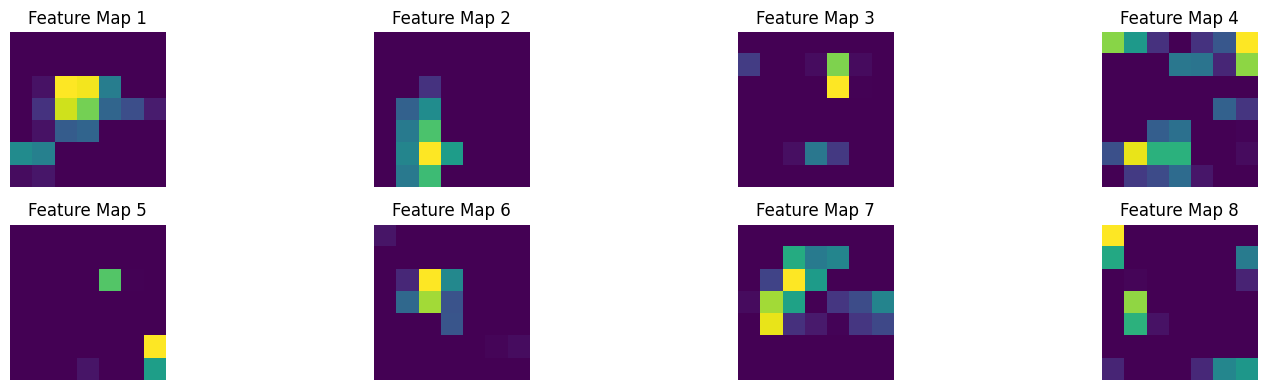

In [9]:

# Display a few channels from the extracted feature tensor
num_feature_maps = 8

plt.figure(figsize=(16, 4))

for i in range(num_feature_maps):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(features[0, :, :, i], cmap="viridis")
    plt.title(f"Feature Map {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()



### Observation
The individual feature maps represent different learned visual patterns. Deeper VGG16 layers generally respond to more abstract patterns than raw pixels, such as combinations of edges, textures, shapes, and object-related structures.


## Step 9: Classification using VGG16 with Top Layers Included


Now VGG16 is loaded with `include_top=True`.

This retains the original fully connected classifier trained on ImageNet. The output vector therefore contains **1000 probabilities**, one for each ImageNet class.


In [10]:

# Load the complete pretrained VGG16 model
vgg16_classifier = VGG16(
    weights="imagenet",
    include_top=True
)

# Predict ImageNet class probabilities
predictions = vgg16_classifier.predict(vgg_input_preprocessed, verbose=0)

print("Classification output shape:", predictions.shape)


553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 17s 0us/step
Classification output shape: (1, 1000)



### Expected Classification Output Shape

\[
(1,\ 1000)
\]

because the pretrained VGG16 top layer contains 1000 ImageNet output classes.


In [11]:

# Decode the top 5 ImageNet predictions
top_predictions = decode_predictions(predictions, top=5)[0]

print("Original CIFAR-10 class:", class_names[label])
print("\nTop 5 VGG16 ImageNet Predictions:")

for rank, (_, class_name, probability) in enumerate(top_predictions, start=1):
    print(f"{rank}. {class_name:25s} : {probability * 100:.2f}%")


35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original CIFAR-10 class: frog

Top 5 VGG16 ImageNet Predictions:
1. rock_python               : 5.68%
2. consomme                  : 5.27%
3. Brabancon_griffon         : 3.62%
4. barn_spider               : 3.28%
5. hot_pot                   : 3.05%



## Why the VGG16 Prediction May Differ from the CIFAR-10 Label

The classification result may not match the CIFAR-10 label exactly because:

1. VGG16 was trained on **ImageNet**, not CIFAR-10.
2. ImageNet contains **1000 fine-grained categories**, while CIFAR-10 contains only 10 broad categories.
3. CIFAR-10 images are originally very small (**32 × 32**) and become blurred or pixelated when enlarged to **224 × 224**.
4. The ImageNet class names do not correspond one-to-one with CIFAR-10 classes.

For example, a CIFAR-10 image labelled **dog** may be classified as a particular ImageNet dog breed rather than simply "dog".


## Step 10: Compare Original, Resized, and One Augmented Image

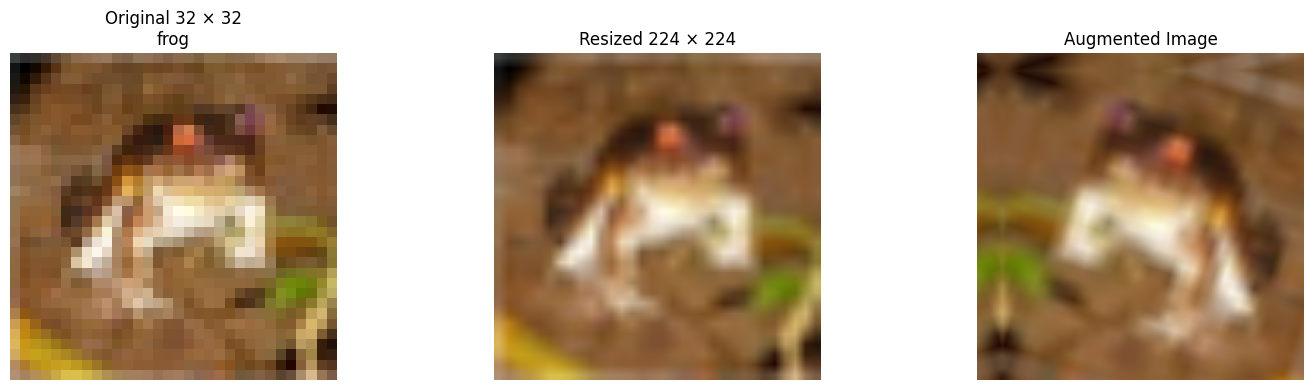

In [12]:

# Create one augmented image for comparison
one_augmented = data_augmentation(image_batch, training=True)[0]
one_augmented = tf.clip_by_value(one_augmented, 0, 255)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title(f"Original 32 × 32\n{class_names[label]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tf.cast(resized_image, tf.uint8))
plt.title("Resized 224 × 224")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tf.cast(one_augmented, tf.uint8))
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()



## Experimental Results

After successful execution, the major observations are:

| Operation | Expected Result |
|---|---|
| Original CIFAR-10 image | Shape = `(32, 32, 3)` |
| Resized image | Shape = `(224, 224, 3)` |
| Batched VGG16 input | Shape = `(1, 224, 224, 3)` |
| VGG16 feature extraction (`include_top=False`) | Shape = `(1, 7, 7, 512)` |
| Total final convolutional features | `25,088` |
| VGG16 classification (`include_top=True`) | Shape = `(1, 1000)` |
| Classification labels | ImageNet classes |

The exact ImageNet predictions and probabilities can vary depending on the selected CIFAR-10 image.



## Result

A CIFAR-10 image was successfully loaded and displayed. The image was resized from **32 × 32** to **224 × 224** and augmented using random image transformations.

The pretrained VGG16 convolutional network was then used as a feature extractor. With `include_top=False`, the image produced a deep feature tensor of approximately:

\[
(1,\ 7,\ 7,\ 512)
\]

Finally, VGG16 with `include_top=True` produced a **1000-dimensional ImageNet class-probability vector**, and the top predicted ImageNet labels were decoded successfully.



## Conclusion

This experiment demonstrates how transfer learning models such as VGG16 can be used for image preprocessing, deep feature extraction, and pretrained image classification.

Resizing makes CIFAR-10 images compatible with VGG16, while augmentation creates useful variations of the input image. The convolutional layers of VGG16 transform the image into high-level feature representations that can later be used for classification, similarity analysis, multimodal learning, or other downstream tasks.

The experiment also highlights the distinction between **feature extraction** and **classification**. Removing the top layers provides reusable deep features, whereas retaining the top layers performs classification according to the original ImageNet label space.



## Optional Extension: Check a Different CIFAR-10 Image

Change `new_index` below and run the cell to inspect another image.

This section is optional and is not required for the main experiment.


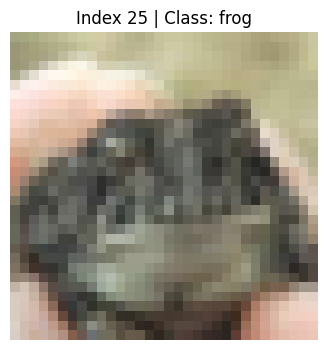

In [13]:

new_index = 25

new_image = x_train[new_index]
new_label = int(y_train[new_index][0])

plt.figure(figsize=(4, 4))
plt.imshow(new_image)
plt.title(f"Index {new_index} | Class: {class_names[new_label]}")
plt.axis("off")
plt.show()
